In [1]:
# 1. Chọn và Khám phá dữ liệu: Chọn một tập dữ liệu thực tế. Sử dụng Pandas để kiểm tra cấu trúc dữ liệu (Shape, Info, Describe).

import pandas as pd

url = "https://raw.githubusercontent.com/pandas-dev/pandas/main/doc/data/titanic.csv"
df = pd.read_csv(url)

print(df.shape)
df.info()
print(df.describe(include="all"))

(891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
        PassengerId    Survived      Pclass                     Name   Sex  \
count    891.000000  891.000000  891.000000                      891   891   
unique          NaN         NaN         NaN                      891     2   


In [7]:
# 2. Làm sạch dữ liệu: Xử lý các giá trị khuyết thiếu (NaN) và các giá trị ngoại lệ (Outliers).

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

url = "https://raw.githubusercontent.com/pandas-dev/pandas/main/doc/data/titanic.csv"
df = pd.read_csv(url)

# Kiểm tra dữ liệu thiếu
print((df.isna().mean() * 100).sort_values(ascending=False).round(1))

# Bỏ hàng nếu thiếu nhãn; tách nhãn và đặc trưng
df = df.dropna(subset=["Survived"]).copy()
y = df["Survived"]
X = df.drop(
    columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"],
    errors="ignore"
)

# Chia dữ liệu trước khi tính giá trị điền thiếu và ngưỡng ngoại lệ
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train = X_train.copy()
X_test = X_test.copy()

num_cols = ["Age", "SibSp", "Parch", "Fare"]
cat_cols = ["Pclass", "Sex", "Embarked"]

# Điền giá trị thiếu: trung vị cho cột số, giá trị phổ biến nhất cho cột phân loại
num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = num_imputer.transform(X_test[num_cols])

X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])
X_test[cat_cols] = cat_imputer.transform(X_test[cat_cols])

# Giới hạn ngoại lệ của Fare theo IQR, với ngưỡng tính từ tập train
q1, q3 = X_train["Fare"].quantile([0.25, 0.75])
iqr = q3 - q1
lower = max(0, q1 - 1.5 * iqr)
upper = q3 + 1.5 * iqr

outlier_count = ((X_train["Fare"] < lower) | (X_train["Fare"] > upper)).sum()
X_train["Fare"] = X_train["Fare"].clip(lower, upper)
X_test["Fare"] = X_test["Fare"].clip(lower, upper)

print("Số ngoại lệ Fare trong train:", outlier_count)
print("Số NaN còn lại trong train:", X_train.isna().sum().sum())

Cabin          77.1
Age            19.9
Embarked        0.2
PassengerId     0.0
Name            0.0
Pclass          0.0
Survived        0.0
Sex             0.0
Parch           0.0
SibSp           0.0
Fare            0.0
Ticket          0.0
dtype: float64
Số ngoại lệ Fare trong train: 91
Số NaN còn lại trong train: 0


In [8]:
# 3. Tiền xử lý: Chuẩn hóa dữ liệu (Scaling) và chia tập dữ liệu thành Train (80%) và Test (20%).

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = ["Age", "SibSp", "Parch", "Fare"]
cat_cols = ["Pclass", "Sex", "Embarked"]

# Chỉ học cách chuẩn hóa/mã hóa từ tập train
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ]
)

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Train sau tiền xử lý:", X_train_scaled.shape)
print("Test sau tiền xử lý:", X_test_scaled.shape)
print("Số dòng train/test:", len(y_train), len(y_test))
print("Nhãn train:\n", y_train.value_counts().sort_index())
print("Nhãn test:\n", y_test.value_counts().sort_index())

# Kiểm tra các cột số đã được chuẩn hóa trên train
scaled_numeric = preprocessor.named_transformers_["num"].transform(
    X_train[num_cols]
)
print("Mean các cột số:", np.round(scaled_numeric.mean(axis=0), 2))
print("Std các cột số:", np.round(scaled_numeric.std(axis=0), 2))

Train sau tiền xử lý: (712, 12)
Test sau tiền xử lý: (179, 12)
Số dòng train/test: 712 179
Nhãn train:
 Survived
0    439
1    273
Name: count, dtype: int64
Nhãn test:
 Survived
0    110
1     69
Name: count, dtype: int64
Mean các cột số: [ 0. -0. -0.  0.]
Std các cột số: [1. 1. 1. 1.]


In [9]:
# 4. Huấn luyện mô hình cơ sở:
# Bài toán Phân loại: Áp dụng Logistic Regression.


from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Mô hình:", type(model).__name__)
print("Các lớp:", model.classes_)
print("Số mẫu train:", X_train_scaled.shape[0])
print("Số đặc trưng:", model.n_features_in_)
print("Kích thước ma trận hệ số:", model.coef_.shape)
print("Kích thước hệ số chặn:", model.intercept_.shape)


Mô hình: LogisticRegression
Các lớp: [0 1]
Số mẫu train: 712
Số đặc trưng: 12
Kích thước ma trận hệ số: (1, 12)
Kích thước hệ số chặn: (1,)


Train: (712, 6)
Test: (179, 6)
Ngoại lệ Fare trong train trước khi giới hạn: 91
Số mẫu test: 179
Accuracy: 0.8156
MSE: 0.1844
Confusion Matrix:
[[97 13]
 [20 49]]
Tổng các ô: 179


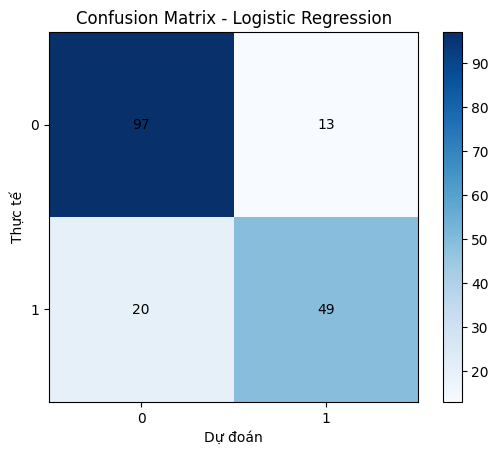

In [3]:
# 5. Đánh giá ban đầu: Sử dụng các chỉ số cơ bản (MSE, Accuracy, Confusion Matrix) và trực quan hóa kết quả.

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mean_squared_error, confusion_matrix

# Đọc dữ liệu từ GitHub
url = "https://raw.githubusercontent.com/pandas-dev/pandas/main/doc/data/titanic.csv"
df = pd.read_csv(url)

# Chọn một số cột đơn giản cho mô hình cơ sở
X = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare"]].copy()
y = df["Survived"]

# Chia dữ liệu 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Điền Age bị thiếu bằng trung vị của tập train
age_median = X_train["Age"].median()
X_train["Age"] = X_train["Age"].fillna(age_median)
X_test["Age"] = X_test["Age"].fillna(age_median)

# Mã hóa Sex: female/male thành số
encoder = LabelEncoder()
X_train["Sex"] = encoder.fit_transform(X_train["Sex"])
X_test["Sex"] = encoder.transform(X_test["Sex"])

# Giới hạn ngoại lệ Fare theo IQR
q1 = X_train["Fare"].quantile(0.25)
q3 = X_train["Fare"].quantile(0.75)
iqr = q3 - q1
lower = max(0, q1 - 1.5 * iqr)
upper = q3 + 1.5 * iqr

outlier_count = (
    (X_train["Fare"] < lower) | (X_train["Fare"] > upper)
).sum()

X_train["Fare"] = X_train["Fare"].clip(lower, upper)
X_test["Fare"] = X_test["Fare"].clip(lower, upper)

# Chuẩn hóa các cột đầu vào
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Huấn luyện Logistic Regression
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# Dự đoán và đánh giá
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Train:", X_train_scaled.shape)
print("Test:", X_test_scaled.shape)
print("Ngoại lệ Fare trong train trước khi giới hạn:", outlier_count)
print("Số mẫu test:", len(y_test))
print(f"Accuracy: {accuracy:.4f}")
print(f"MSE: {mse:.4f}")
print("Confusion Matrix:")
print(cm)
print("Tổng các ô:", cm.sum())

# Vẽ Confusion Matrix
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks([0, 1], ["0", "1"])
plt.yticks([0, 1], ["0", "1"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()